In [1]:
import torch
import os
import monai.transforms as mt
import monai.data as md
import scipy.io as sio
import numpy as np
from liutuo_utils import compare_3d_jet,compare_3d,donkey_noise_like
import matplotlib.pyplot as plt
import pandas as pd
device_id =2

# 设置 PyTorch 的默认 CUDA 设备
torch.cuda.set_device(device_id)

# 确认当前默认 CUDA 设备
current_device = torch.cuda.current_device()
print(f"Switched to CUDA device: {current_device}")

/home/data/liutuo/.conda/envs/chouchou/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Switched to CUDA device: 2


In [2]:
from transformers import AutoProcessor, AutoModel

# 使用本地路径加载处理器和模型
local_model_path = "/home/data/liutuo/code/BiomedCLIP"

processor = AutoProcessor.from_pretrained(local_model_path, trust_remote_code=True)
model = AutoModel.from_pretrained(local_model_path, trust_remote_code=True)

In [3]:
from transformers import AutoProcessor, AutoModel
import torch
# 使用本地路径加载处理器和模型
local_model_path = "/home/data/liutuo/code/BiomedCLIP"
processor = AutoProcessor.from_pretrained(local_model_path, trust_remote_code=True)
model = AutoModel.from_pretrained(local_model_path, trust_remote_code=True)

# 将模型转移到设备
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)
model.eval()
context_length = 256

# modal_information = [
#     'T1-weighted imaging is an MRI technique that emphasizes tissues with lower water content. In T1-weighted images, bright areas represent fatty tissues, while dark areas indicate tissues with higher water content, such as fluids or edema.',
#     'PET (Positron Emission Tomography) visualizes metabolic processes using FDG (Fluorodeoxyglucose) as the radioactive tracer. Bright areas indicate high glucose uptake, like active brain regions or tumors, while dark areas show lower activity. PET pixel values represent tracer concentration, with higher values indicating greater metabolic activity.',
#     'CT (Computed Tomography) visualizes internal structures using X-rays. Bright areas (high density) represent dense tissues like bone, while dark areas (low density) indicate less dense tissues, such as air or fat. CT density values correlate with tissue composition, while PET density values reflect metabolic activity, with high values indicating increased glucose uptake.'
# ]

modal_information = [
    'T1-weighted MRI highlights tissues with low water content. Bright areas represent fatty tissues like brain white matter or subcutaneous fat. Dark areas indicate high water content tissues such as fluids, edema, or cerebrospinal fluid. This contrast helps to differentiate between various soft tissues based on their water content and composition, useful for detecting lesions or structural abnormalities.',
    
    'PET (Positron Emission Tomography) utilizes FDG (Fluorodeoxyglucose) as a radioactive tracer to visualize metabolic activity. Areas with high glucose uptake appear bright on PET images, indicating regions of high metabolic activity such as active brain regions, tumors, or inflamed tissues. Conversely, areas with low glucose uptake are darker. This imaging is crucial for evaluating tumor activity, brain function, and other metabolic processes by measuring tracer concentration.',
    
    'CT (Computed Tomography) uses X-rays to produce detailed images of internal body structures. Dense tissues like bone appear bright due to high X-ray absorption, while less dense tissues like air or fat appear dark. CT images are crucial for evaluating anatomical structures, diagnosing fractures, tumors, and internal bleeding. Unlike PET, which shows metabolic activity, CT primarily provides structural and density information.'
]
# 使用 tokenizer 进行文本处理
tokenizer = processor.tokenizer
inputs = tokenizer(modal_information, padding=True, truncation=True, return_tensors="pt", max_length=context_length)
texts = inputs['input_ids'].to(device)

# 计算文本嵌入特征
with torch.no_grad():
    text_features = model.get_text_features(texts)  # Replace `get_text_features` with the correct method
    print(text_features.shape, text_features.dtype)  # 打印嵌入特征的形状和数据类型


torch.Size([3, 512]) torch.float32


In [4]:
import os
import pandas as pd
import torch
from transformers import AutoProcessor, AutoModel
import scipy.io as sio

# 读取CSV文件并创建Subject到Description和Group的映射
label_path1 = "/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/ADNI1_imdb_with_meta_description.csv"
label_path2 = "/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/ADNI2_imdb_with_meta_description.csv"

label1 = pd.read_csv(label_path1)
label2 = pd.read_csv(label_path2)

label1_dict = dict(zip(label1["Subject"], label1["Group"]))
label2_dict = dict(zip(label2["Subject"], label2["Group"]))

label1_desc_dict = dict(zip(label1["Subject"], label1["description"]))
label2_desc_dict = dict(zip(label2["Subject"], label2["description"]))

# 使用本地路径加载处理器和模型
local_model_path = "/home/data/liutuo/code/BiomedCLIP"
processor = AutoProcessor.from_pretrained(local_model_path, trust_remote_code=True)
model = AutoModel.from_pretrained(local_model_path, trust_remote_code=True)

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)
model.eval()

# 定义函数以读取.mat文件
def mat_load(mat_file_dir):
    mat = sio.loadmat(mat_file_dir)
    image = mat["IMG"]
    return image

# 获取路径中的数据列表
def get_data_list_from_path(path):
    data_list = [os.path.join(path, data) for data in os.listdir(path)]
    return data_list

# 获取路径中的数据并创建映射
def get_data_from_path(path, label_dict):
    data_all = []
    for data in os.listdir(path):
        image = os.path.join(path, data)
        name = data[:-4]
        try:
            label = label_dict[name]
        except KeyError:
            continue
        data_all.append({"image": image, "name": name, "label": label})
    return data_all

# 获取配对数据并附加Description
def get_data_from_path_paired_with_description(path, label_dict, label_desc_dict, mri_name_image_dict):
    data_all = []
    for data in os.listdir(path):
        pet = os.path.join(path, data)
        name = data[:-4]
        try:
            mri = mri_name_image_dict[name]
            label = label_dict[name]
            description = label_desc_dict[name]
        except KeyError:
            continue
        data_all.append({
            "pet": pet,
            "mri": mri,
            "name": name,
            "label": label,
            "description": description,
        })
    return data_all

# 设置路径
mri_path = "/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/MRI"
pet_path = "/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET"

# 获取MRI数据并创建映射
data_all = get_data_from_path(mri_path, label1_dict)
data_all_adni2 = get_data_from_path(mri_path, label2_dict)

mri_name_image_dict = dict(zip([data["name"] for data in data_all],
                               [data["image"] for data in data_all]))
mri_name_image_dict_adni2 = dict(zip([data["name"] for data in data_all_adni2],
                                     [data["image"] for data in data_all_adni2]))

# 获取配对数据并附加Description
paired_all_with_desc1 = get_data_from_path_paired_with_description(pet_path, label1_dict, label1_desc_dict, mri_name_image_dict)
paired_all_with_desc2 = get_data_from_path_paired_with_description(pet_path, label2_dict, label2_desc_dict, mri_name_image_dict_adni2)

# 合并两个数据集
paired_all_with_desc = paired_all_with_desc1 + paired_all_with_desc2

# 将Description转化为BiomedCLIP嵌入
modal_information = [data["description"] for data in paired_all_with_desc]
text_inputs = processor.tokenizer(modal_information, padding=True, truncation=True, return_tensors="pt", max_length=256).to(device)

with torch.no_grad():
    desc_text_features = model.get_text_features(text_inputs['input_ids'])  # 使用实际的特征提取方法
    print(desc_text_features.shape, desc_text_features.dtype)


torch.Size([1129, 512]) torch.float32


In [5]:
print(paired_all_with_desc)

[{'pet': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET/033_S_1281.mat', 'mri': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/MRI/033_S_1281.mat', 'name': '033_S_1281', 'label': 'AD', 'description': 'Subject is a 78-year-old female with a weight of 69.9 kg. The global Clinical Dementia Rating (CDR) score, which assesses dementia severity (0: no dementia to 3: severe dementia), is 1.0. The Mini-Mental State Examination (MMSE) score, assessing cognitive function (0: severe impairment to 30: normal), is 24.0. The Geriatric Depression Scale (GDS) score, screening depression (0: no depression to 15: severe depression), is 5.0. The Functional Activities Questionnaire (FAQ) score, assessing daily activity impairment (0: no impairment to 30: severe impairment), is 22.0.'}, {'pet': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET/131_S_0409.mat', 'mri': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/MRI/131_S_0409.mat', 'name': '131_S_0409', 'label': 'MCI', 'descr

In [6]:
c_mri= text_features[0].unsqueeze(0).to(dtype=torch.float32).to(device)
c_pet= text_features[1].unsqueeze(0).to(dtype=torch.float32).to(device)
c_ct= text_features[2].unsqueeze(0).to(dtype=torch.float32).to(device)
print(c_ct.shape)

torch.Size([1, 512])


In [7]:
# 修改后的函数，用于获取配对数据并附加Description和text_mri, text_pet
def get_data_from_path_paired_with_description(path, label_dict, label_desc_dict, mri_name_image_dict):
    data_all = []
    for i, data in enumerate(os.listdir(path)):
        pet = os.path.join(path, data)
        name = data[:-4]
        try:
            mri = mri_name_image_dict[name]
            label = label_dict[name]
            description = label_desc_dict[name]
        except KeyError:
            continue
        data_all.append({
            "pet": pet,
            "mri": mri,
            "name": name,
            "label": label,
            "description": description,
            "mri_index": i,
            "pet_index": i,
        })
    return data_all

# 使用新的函数生成配对数据
paired_all_with_desc1 = get_data_from_path_paired_with_description(
    pet_path, label1_dict, label1_desc_dict, mri_name_image_dict
)
paired_all_with_desc2 = get_data_from_path_paired_with_description(
    pet_path, label2_dict, label2_desc_dict, mri_name_image_dict_adni2
)

# 合并两个数据集
paired_all_with_desc = paired_all_with_desc1 + paired_all_with_desc2

# # 过滤掉label不是CN或AD的样本
# paired_all_with_desc = [data for data in paired_all_with_desc if data["label"] in ["CN", "AD"]]

# 输出检查
print(paired_all_with_desc[0].keys())  # 检查新的key是否成功加入
print(paired_all_with_desc[0].values()) 
print(len(paired_all_with_desc))
for new_index, data in enumerate(paired_all_with_desc):
    data['index'] = new_index


dict_keys(['pet', 'mri', 'name', 'label', 'description', 'mri_index', 'pet_index'])
dict_values(['/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET/033_S_1281.mat', '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/MRI/033_S_1281.mat', '033_S_1281', 'AD', 'Subject is a 78-year-old female with a weight of 69.9 kg. The global Clinical Dementia Rating (CDR) score, which assesses dementia severity (0: no dementia to 3: severe dementia), is 1.0. The Mini-Mental State Examination (MMSE) score, assessing cognitive function (0: severe impairment to 30: normal), is 24.0. The Geriatric Depression Scale (GDS) score, screening depression (0: no depression to 15: severe depression), is 5.0. The Functional Activities Questionnaire (FAQ) score, assessing daily activity impairment (0: no impairment to 30: severe impairment), is 22.0.', 4, 4])
1129


In [8]:
for new_index, data in enumerate(paired_all_with_desc):
    data['mri_index'] = new_index
    data['pet_index'] = new_index

In [9]:
train_data = paired_all_with_desc[:800]

val_data = paired_all_with_desc[800:]

# 输出检查
print(f"训练集大小: {len(train_data)}") 
print(f"验证集大小: {len(val_data)}")   


训练集大小: 800
验证集大小: 329


In [10]:
print(val_data)

[{'pet': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET/051_S_5005.mat', 'mri': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/MRI/051_S_5005.mat', 'name': '051_S_5005', 'label': 'AD', 'description': 'Subject is a 78-year-old male with a weight of 65.0 kg. The global Clinical Dementia Rating (CDR) score, which assesses dementia severity (0: no dementia to 3: severe dementia), is 2.0. The Mini-Mental State Examination (MMSE) score, assessing cognitive function (0: severe impairment to 30: normal), is 20.0. The Geriatric Depression Scale (GDS) score, screening depression (0: no depression to 15: severe depression), is 0.0. The Functional Activities Questionnaire (FAQ) score, assessing daily activity impairment (0: no impairment to 30: severe impairment), is 25.0.', 'mri_index': 800, 'pet_index': 800, 'index': 800}, {'pet': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET/027_S_2245.mat', 'mri': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/MRI/027_S_2245.ma

In [11]:
def mri_index_transform(x):
    return torch.cat([desc_text_features[x].unsqueeze(0), c_mri], dim=0)

def pet_index_transform(x):
    return torch.cat([desc_text_features[x].unsqueeze(0), c_pet], dim=0)

from monai.data import CacheDataset, DataLoader
from monai.data import CacheNTransDataset
import monai.data as md
from monai.data import CacheDataset, DataLoader
from monai.data import CacheNTransDataset
import monai.data as md
train_transforms=mt.Compose([
    mt.Lambdad(keys=["pet","mri"],func=mat_load),
    mt.EnsureChannelFirstd(keys=["pet","mri"],channel_dim='no_channel'),
    mt.Orientationd(keys=["pet","mri"],axcodes="LPI"),
    mt.CropForegroundd(keys=["pet","mri"],source_key="mri"),
    #mt.NormalizeIntensityd(keys=["pet","mri"]),
    mt.HistogramNormalized(keys=["pet","mri"]),
    mt.ResizeWithPadOrCropd(keys=["pet","mri"],spatial_size=(160,192,160)),
    mt.Spacingd(keys=["pet","mri"],pixdim=(1.0,1.0,1.0), mode=("bilinear")),
    mt.NormalizeIntensityd(keys=["pet","mri"]),
    mt.ScaleIntensityd(keys=["pet","mri"],minv=0,maxv=1),
    mt.Lambdad(keys=["mri_index"], func=mri_index_transform),
    mt.Lambdad(keys=["pet_index"], func=pet_index_transform),
#     mt.Lambdad(keys=["pet_index"],func=lambda x:paired_all_with_desc[x]),
])
val_transforms=mt.Compose([
    mt.Lambdad(keys=["pet","mri"],func=mat_load),
    mt.EnsureChannelFirstd(keys=["pet","mri"],channel_dim='no_channel'),
    mt.Orientationd(keys=["pet","mri"],axcodes="LPI"),
    mt.CropForegroundd(keys=["pet","mri"],source_key="mri"),
    mt.HistogramNormalized(keys=["pet","mri"]),
    mt.ResizeWithPadOrCropd(keys=["pet","mri"],spatial_size=(160,192,160)),
    mt.Spacingd(keys=["pet","mri"],pixdim=(1.0,1.0,1.0), mode=("bilinear")),
    mt.NormalizeIntensityd(keys=["pet","mri"]),
    mt.ScaleIntensityd(keys=["pet","mri"],minv=0,maxv=1),
    mt.Lambdad(keys=["mri_index"], func=mri_index_transform),
    mt.Lambdad(keys=["pet_index"], func=pet_index_transform),

])


train_ds = CacheDataset(data=train_data, transform=train_transforms,num_workers=20)
train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, num_workers=0)    

val_ds = CacheDataset(data=val_data, transform=val_transforms,num_workers=20)
val_loader = DataLoader(val_ds,  batch_size=1,shuffle=False, num_workers=0)

monai.transforms.croppad.dictionary CropForegroundd.__init__:allow_smaller: Current default value of argument `allow_smaller=True` has been deprecated since version 1.2. It will be changed to `allow_smaller=False` in version 1.5.
Loading dataset: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 329/329 [00:24<00:00, 13.55it/s]


Subject name: 051_S_5005


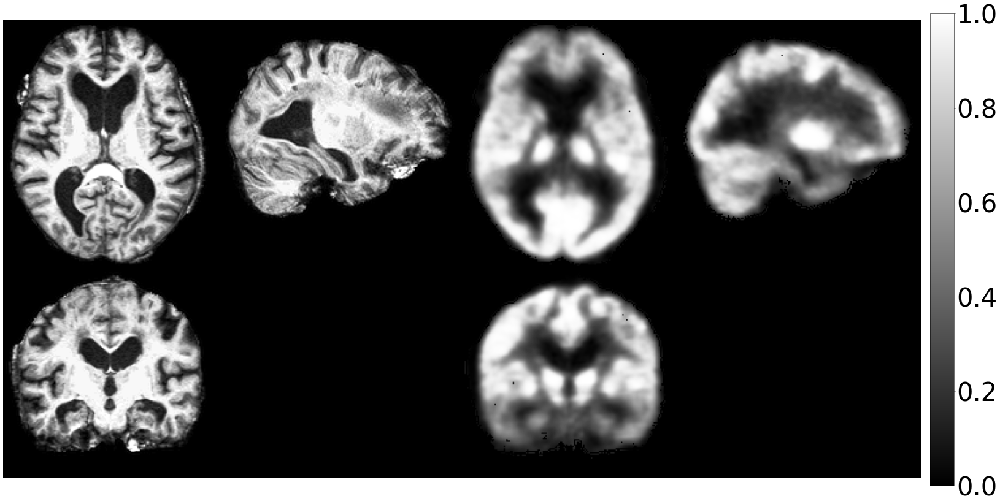

torch.Size([1, 1, 160, 192, 160])
torch.Size([1, 1, 160, 192, 160])


In [12]:
for batch in val_loader:
    image_1 = batch["mri"]
    label_1 = batch["pet"]
    names = batch["name"]  # Extract subject information

    # Print or visualize subject information
    for idx, name in enumerate(names):
        print(f"Subject name: {name}")

    compare_3d([image_1, label_1])
    break  # Uncomment to compare only the first batch
print(image_1.shape)
print(label_1.shape)


In [13]:
from monai.networks.nets import ViT, ViTAutoEnc, SwinUNETR


roi = (160,192,160)
batch_size = 1
sw_batch_size = 2
infer_overlap = 0.5
max_epochs = 500
val_every = 10


model = SwinUNETR(
    img_size=(160,192,160),
    in_channels=1,
    out_channels=1,
    feature_size=48,
    drop_rate=0.0,
    attn_drop_rate=0.0,
    dropout_path_rate=0.0,
    use_checkpoint=False,
).to(device)
optimizer = torch.optim.Adam(params=model.parameters(), lr=1e-5)

monai.networks.nets.swin_unetr SwinUNETR.__init__:img_size: Argument `img_size` has been deprecated since version 1.3. It will be removed in version 1.5. The img_size argument is not required anymore and checks on the input size are run during forward().


`torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
Epoch 0: 100%|████████| 800/800 [11:48<00:00,  1.13it/s, loss=0.00702]


Epoch 1 Validation loss 0.005159522872418165
epoch: 1
learning rate: 1e-05
Saved all parameters!



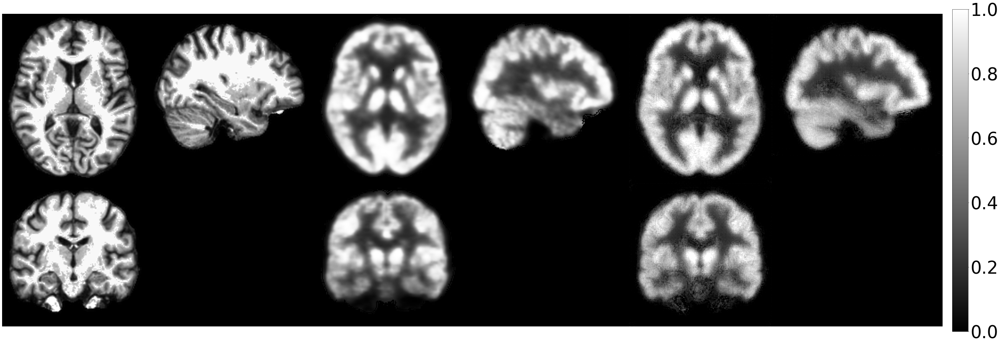

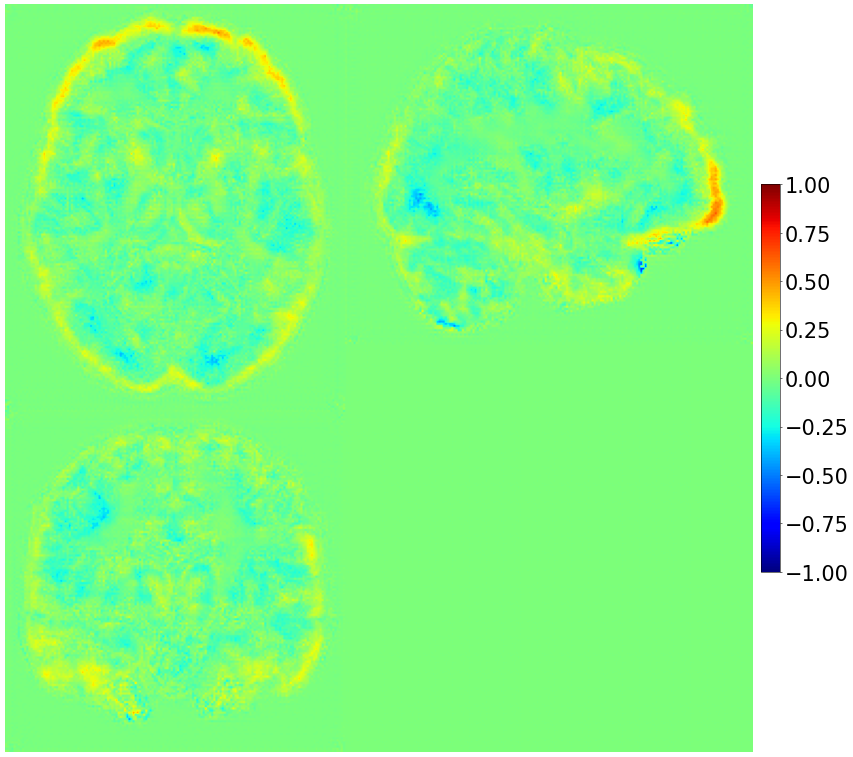

Average SSIM: tensor([[0.7297]], device='cuda:2')
Average PSNR: tensor([[22.8739]], device='cuda:2')


Epoch 10: 100%|████████| 800/800 [11:49<00:00,  1.13it/s, loss=0.0022]


Epoch 11 Validation loss 0.006688521709293127
epoch: 11
learning rate: 1e-05
Saved all parameters!



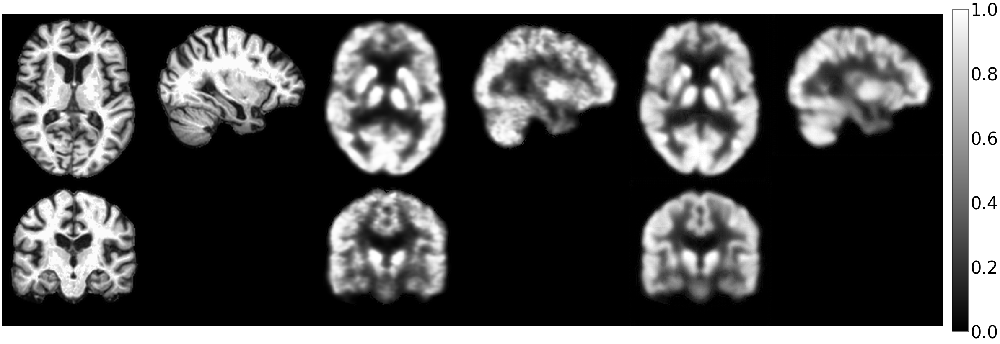

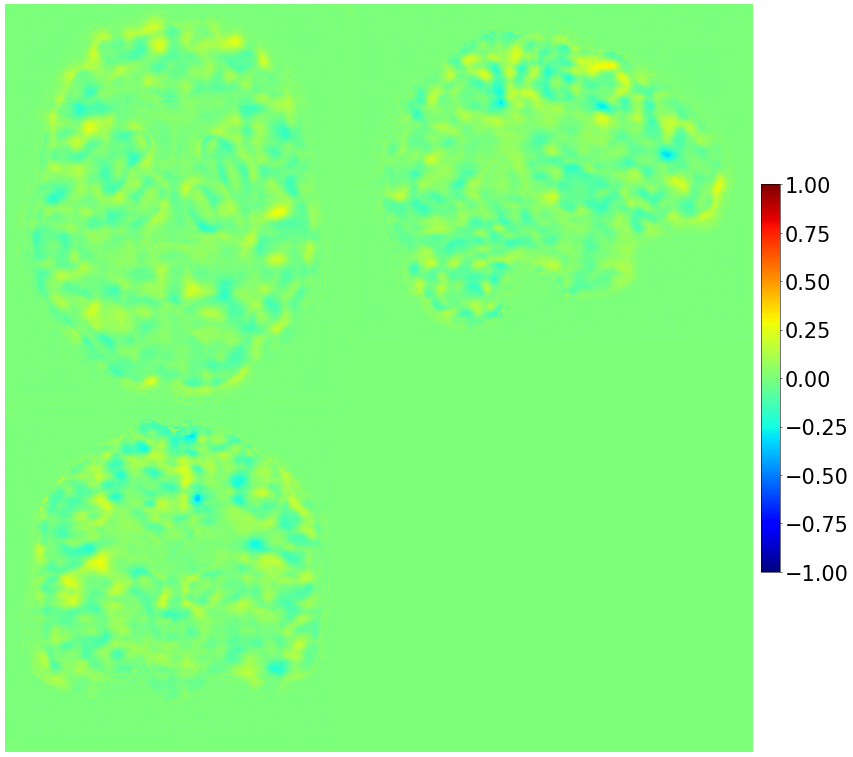

Average SSIM: tensor([[0.8928]], device='cuda:2')
Average PSNR: tensor([[28.1559]], device='cuda:2')


Epoch 20: 100%|███████| 800/800 [11:47<00:00,  1.13it/s, loss=0.00152]


Epoch 21 Validation loss 0.00808459345716983
epoch: 21
learning rate: 1e-05
Saved all parameters!



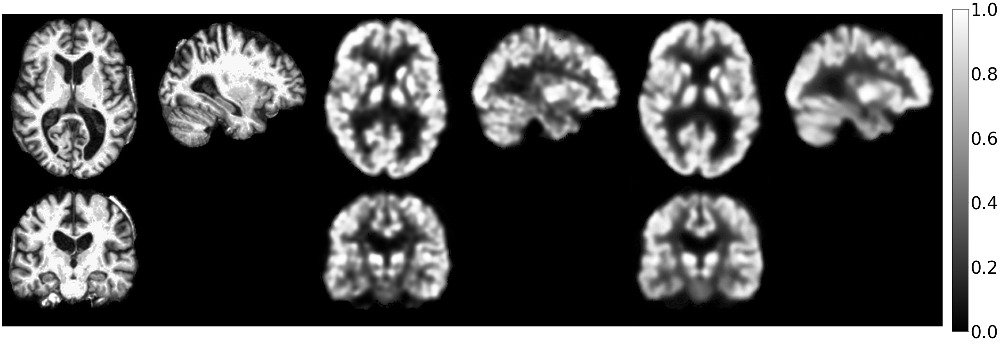

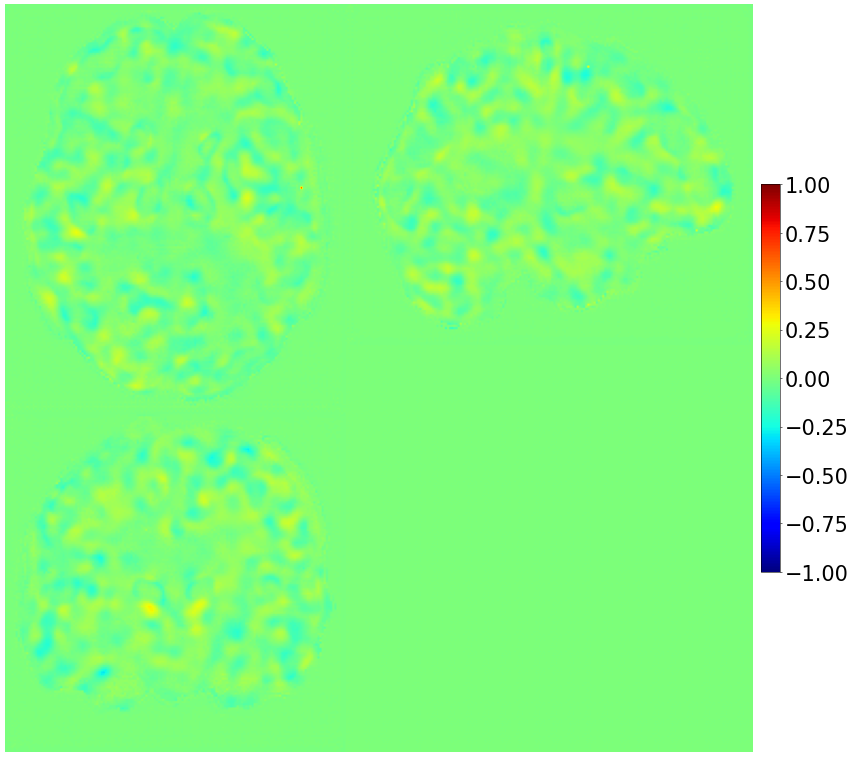

Average SSIM: tensor([[0.9165]], device='cuda:2')
Average PSNR: tensor([[28.5509]], device='cuda:2')


Epoch 30: 100%|████████| 800/800 [11:47<00:00,  1.13it/s, loss=0.0012]


Epoch 31 Validation loss 0.010267920210026205
epoch: 31
learning rate: 1e-05
Saved all parameters!



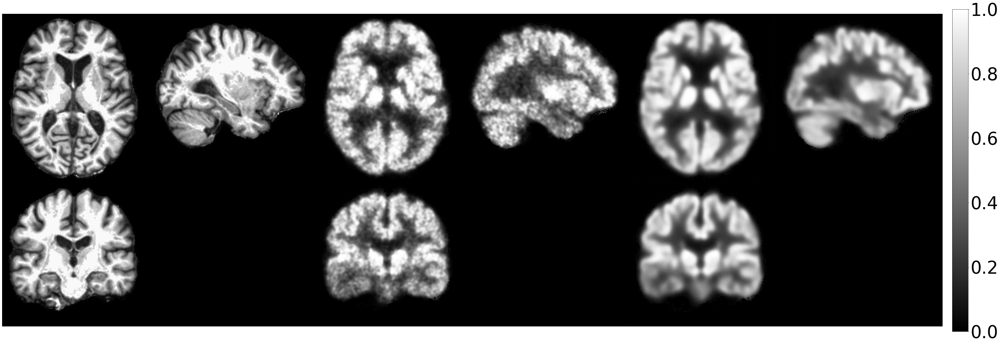

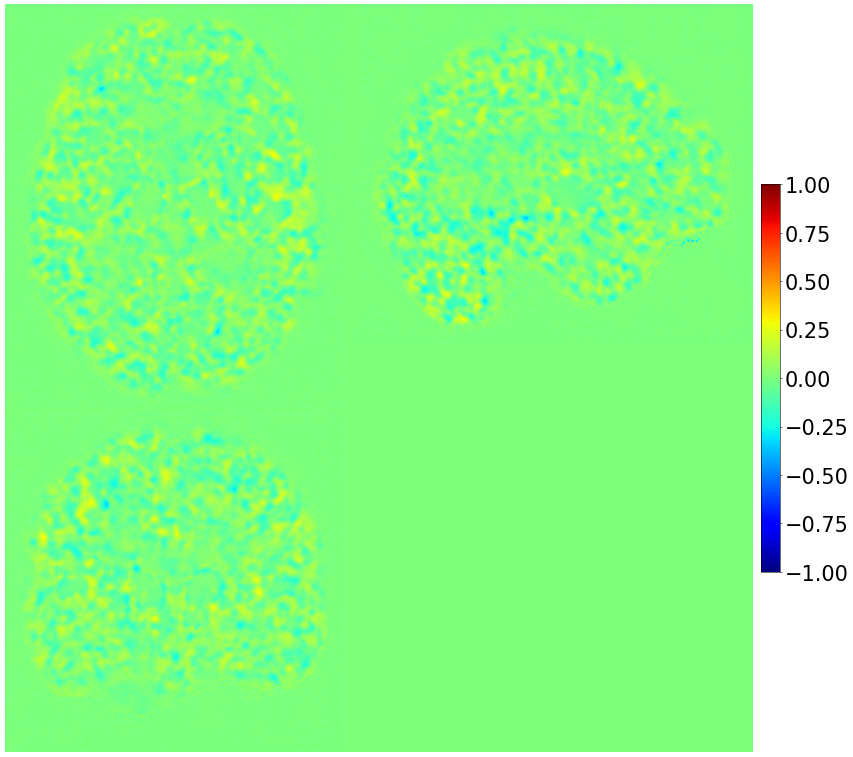

Average SSIM: tensor([[0.8648]], device='cuda:2')
Average PSNR: tensor([[26.6088]], device='cuda:2')


Epoch 39:  19%|█▏    | 153/800 [04:43<19:59,  1.85s/it, loss=0.000998]


KeyboardInterrupt: 

In [16]:
from torch.cuda.amp import GradScaler, autocast
import os

import matplotlib.pyplot as plt
import torch
import json
import torch.nn as nn

import torch.nn.functional as F
from monai import transforms
from monai.config import print_config
from monai import data
from monai.utils import first, set_determinism
from torch.cuda.amp import GradScaler, autocast
from monai.data import CacheDataset, DataLoader
from monai.networks.nets import ViT, ViTAutoEnc, SwinUNETR
from tqdm import tqdm

from generative.inferers import DiffusionInferer
from generative.networks.nets import AutoencoderKL, DiffusionModelUNet
from generative.networks.schedulers import DDPMScheduler, DDIMScheduler
import random
import time
import matplotlib.pyplot as plt
import numpy as np

from generative.metrics import SSIMMetric
from monai.metrics import (MAEMetric,MSEMetric,PSNRMetric,)
checkpoint_dir = '/home/data/liutuo/code/checkpoint/swinunter'
n_epochs = 800
val_interval = 10 #10
epoch_loss_list = []
val_epoch_loss_list = []
val_epoch_loss = 0
start_epoch = 0
from generative.metrics import SSIMMetric
from monai.metrics import (MAEMetric,MSEMetric,PSNRMetric,)
ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0,kernel_size=7)
psnr_metric=PSNRMetric(1.0)
clip_sample_min = 0  # 设置合适的最小值
clip_sample_max = 1.0   # 设置合适的最大值

scaler = GradScaler()


for epoch in range(start_epoch, n_epochs):
    epoch
    model.train()
    epoch_loss = 0

    progress_bar = tqdm(enumerate(train_loader), total=len(train_loader), ncols=70)
    progress_bar.set_description(f"Epoch {epoch}")

    for step, data in progress_bar:
        images = data["mri"].to(device)  
        targets = data["pet"].to(device)  

 

        optimizer.zero_grad(set_to_none=True)
    
        with autocast(enabled=True):

            t1ce_pre = model(images)
            loss = F.mse_loss(targets.float(), t1ce_pre.float())

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        epoch_loss += loss.item()

        progress_bar.set_postfix({"loss": epoch_loss / (step + 1)})

    epoch_loss_list.append(epoch_loss / (step + 1))
    
    if (epoch) % val_interval == 0 or (epoch == 0):
        model.eval()
        ssim_values = []
        psnr_values = []

        with torch.no_grad():
            for step, batch in enumerate(val_loader):
                images = data["mri"].to(device)  # 确保将张量加载到 GPU
                targets = data["pet"].to(device)  # 确保目标也在 GPU

                t1ce_pre= model(images)
                t1ce_pre= torch.clamp(t1ce_pre, min=clip_sample_min, max=clip_sample_max)
                val_loss =F.mse_loss(targets.float(), t1ce_pre.float())
                val_epoch_loss += val_loss.item()
                torch.cuda.empty_cache()
            print("Epoch", epoch + 1, "Validation loss", val_epoch_loss / (step + 1))
            val_epoch_loss_list.append(val_epoch_loss / (step + 1))
            # Saving model parameters
            print('epoch:', epoch + 1)
            print('learning rate:', optimizer.state_dict()['param_groups'][0]['lr'])
            checkpoint = {
                'model': model.state_dict(),
                'optimizer': optimizer.state_dict(),
                'epoch': epoch
            }
            torch.save(checkpoint, f'{checkpoint_dir}/swinunter_{epoch + 1}.pth')
            print('Saved all parameters!\n')
        

            ssim_value = ssim_metric(targets, t1ce_pre)
            psnr_value = psnr_metric(targets, t1ce_pre)
            # print(f"SSIM: {ssim_value.mean().item()}")
            # print(f"PSNR: {psnr_value.mean().item()}") 
            # 将当前批次的 SSIM 和 PSNR 值添加到列表中
            ssim_values.append(ssim_value)
            psnr_values.append(psnr_value)
            current_img =  t1ce_pre.to('cpu')
            labels = targets.to('cpu')
            compare_3d([images,labels, current_img])
            compare_3d_jet([current_img - labels])



        # 计算平均 SSIM 和 PSNR 值
        average_ssim = sum(ssim_values) / len(ssim_values)
        average_psnr = sum(psnr_values) / len(psnr_values)

        print(f"Average SSIM: {average_ssim}")
        print(f"Average PSNR: {average_psnr}")


You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


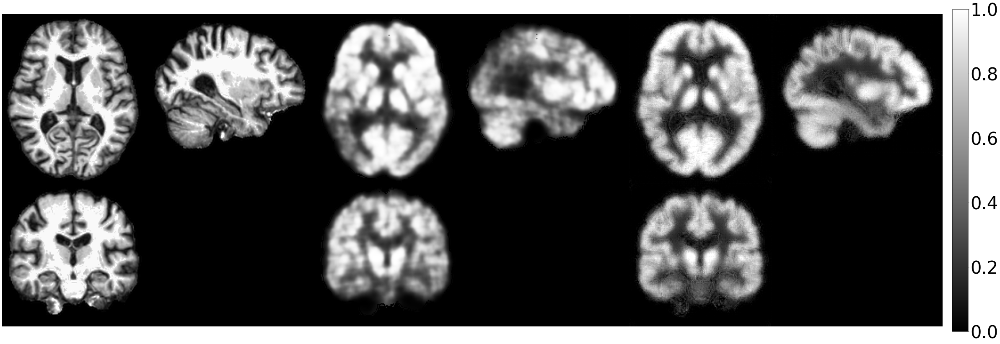

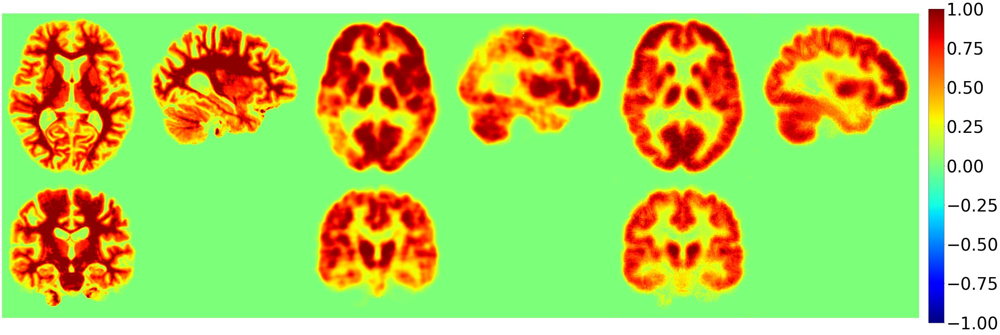

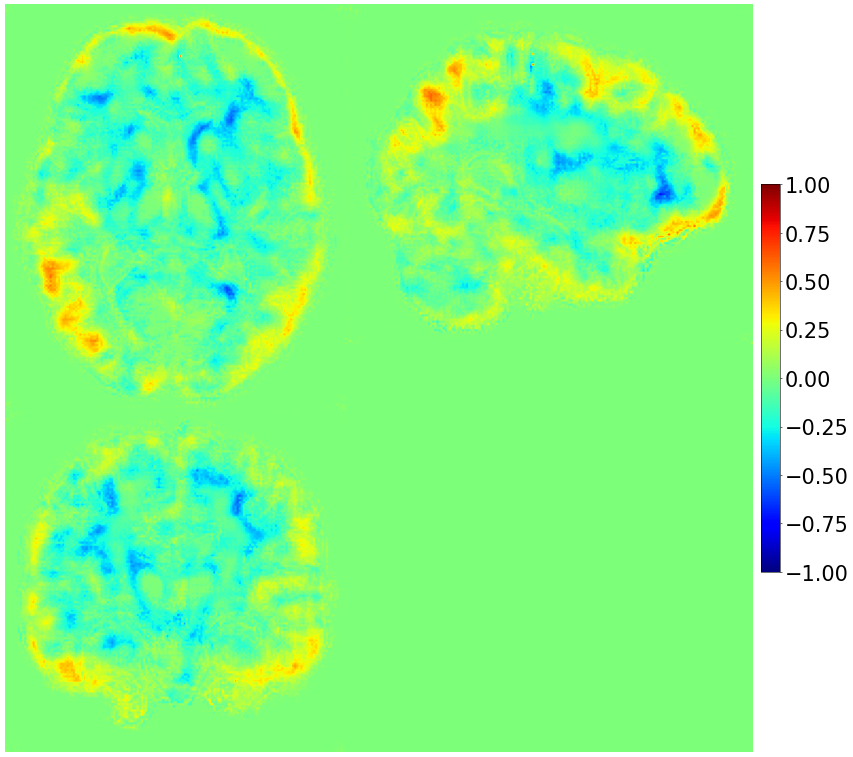

SSIM: 0.7392916679382324
PSNR: 19.827280044555664


In [14]:
import torch
import numpy as np
from tqdm import tqdm
from generative.metrics import SSIMMetric

# 加载保存的模型参数
checkpoint_path = "/home/data/liutuo/code/checkpoint/swinunter/swinunter_1.pth"
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(checkpoint['model'])
optimizer.load_state_dict(checkpoint['optimizer'])
model.eval()  # Set the model to evaluation mode
clip_sample_min = 0  # 设置合适的最小值
clip_sample_max = 1.0   # 设置合适的最大值
model.to(device)

# 初始化SSIM度量
ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0, kernel_size=11)

# 遍历数据集，查找特定样本名称
for batch in train_loader:
    names = batch["name"]  # 提取样本名称

    # 查找名称为 "130_S_0460" 的样本
    if "022_S_0543" not in names:
        continue  # 如果没有找到该样本，继续下一个 batch

    # 获取该样本的 MRI 输入图像和 PET 标签
    images= batch["mri"].to(device)
    labels = batch["pet"].to(device)
    pet_index = batch["pet_index"].to(device)


    x_t = images
    N_sample =1
    N_sample_tensor = torch.tensor(N_sample, dtype=torch.float32)
    progress_bar = [(i / N_sample) for i in range(N_sample)]
    
    # for t in progress_bar:
    #     with autocast(device_type='cuda', enabled=False):

            

    x_t = model(x_t).to(x_t.device)
            
    x_t = torch.clamp(x_t, min=clip_sample_min, max=clip_sample_max)
    # 将结果移回CPU
    current_img = x_t.to('cpu')
    labels = labels.to('cpu')
    from generative.metrics import SSIMMetric
    from monai.metrics import (MAEMetric, MSEMetric, PSNRMetric,)

    # 计算当前采样的SSIM
    ssim_value = ssim_metric(labels, current_img)

    # 可视化采样结果
    compare_3d([images, labels, current_img])
    compare_3d_jet([images, labels, current_img])
    compare_3d_jet([current_img - labels])

    # 计算并输出PSNR和SSIM
    psnr_metric = PSNRMetric(1.0)
    ssim_value = ssim_metric(labels, current_img)
    psnr_value = psnr_metric(labels, current_img)

    print(f"SSIM: {ssim_value.mean().item()}")
    print(f"PSNR: {psnr_value.mean().item()}")

    # 找到并处理完 "130_S_0460" 样本后，退出循环
    break

In [15]:
import os
import torch
import nibabel as nib
import numpy as np
from monai.transforms import Orientationd, EnsureChannelFirstd
from monai.data import MetaTensor

# 保存路径
save_dir = "/home/data/liutuo/code/test"
os.makedirs(save_dir, exist_ok=True)

# 将张量转换为 NIfTI 文件并保存
def save_nifti(tensor, save_path, orientation_axcodes="LPI"):
    # 去掉前两维度，变成 3D
    array = tensor.squeeze().detach().cpu().numpy()


    # 创建 NIfTI 图像
    nii_img = nib.Nifti1Image(array, affine=np.eye(4))
    
    # 转换为 MetaTensor
    meta_tensor = MetaTensor(array, affine=np.eye(4))
    
    # 调整方向为 LPI
    orientation =mt.Orientationd(keys=["image"], axcodes="LPI")
    oriented_tensor = orientation({"image": meta_tensor})["image"]
    
    # 保存为 NIfTI 文件
    oriented_array = oriented_tensor.numpy()
    oriented_nii_img = nib.Nifti1Image(oriented_array, affine=np.eye(4))
    nib.save(oriented_nii_img, save_path)
    print(f"Saved: {save_path}")

# 保存 `input_img`
save_nifti(images, os.path.join(save_dir, "input_img.nii.gz"))

# 保存 `labels`
save_nifti(labels, os.path.join(save_dir, "labels.nii.gz"))

# 保存 `current_img`
save_nifti(current_img, os.path.join(save_dir, "current_img.nii.gz"))

Saved: /home/data/liutuo/code/test/input_img.nii.gz


axcodes ('LPI') length is smaller than number of input spatial dimensions D=2.
Orientation: spatial shape = (192, 160), channels = 160,please make sure the input is in the channel-first format.


Saved: /home/data/liutuo/code/test/labels.nii.gz
Saved: /home/data/liutuo/code/test/current_img.nii.gz


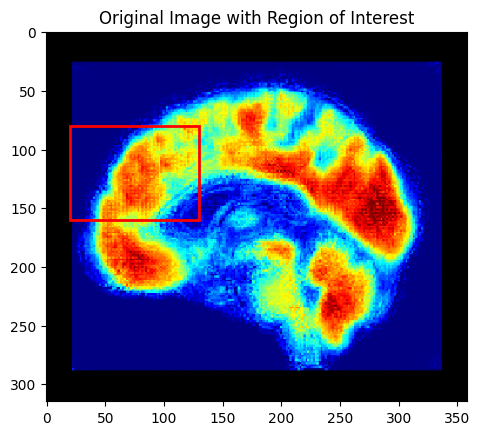

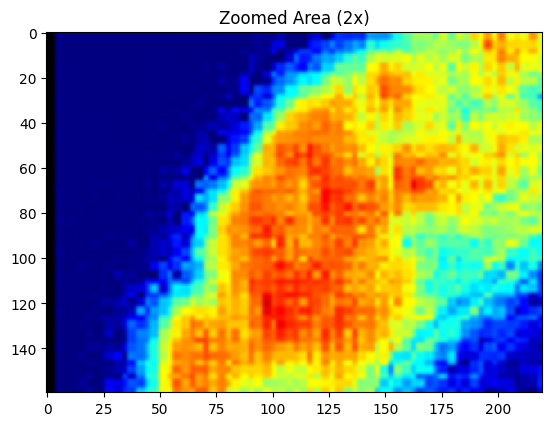

In [37]:
import matplotlib.pyplot as plt
from PIL import Image
import matplotlib.patches as patches

# 加载图片
image_path = '/home/data/liutuo/code/test/picture/图片44.png'
image = Image.open(image_path)

# 定义感兴趣区域的四个边界点
# 边界格式 (left, upper, right, lower)
area_of_interest = (20, 80, 130, 160)

# 创建可视化
fig, ax = plt.subplots()
ax.imshow(image)

# 绘制红色矩形框
rect = patches.Rectangle(
    (area_of_interest[0], area_of_interest[1]),  # 左上角坐标
    area_of_interest[2] - area_of_interest[0],  # 矩形宽度
    area_of_interest[3] - area_of_interest[1],  # 矩形高度
    linewidth=2,
    edgecolor='red',
    facecolor='none'
)
ax.add_patch(rect)

# 设置坐标轴
ax.set_title("Original Image with Region of Interest")
plt.show()

# 裁剪感兴趣区域
cropped_image = image.crop(area_of_interest)

# 放大图片
zoom_factor = 2
width, height = cropped_image.size
resized_image = cropped_image.resize((width * zoom_factor, height * zoom_factor))

# 可视化放大的图片
fig, ax = plt.subplots()
ax.imshow(resized_image)
ax.set_title("Zoomed Area (2x)")
plt.show()


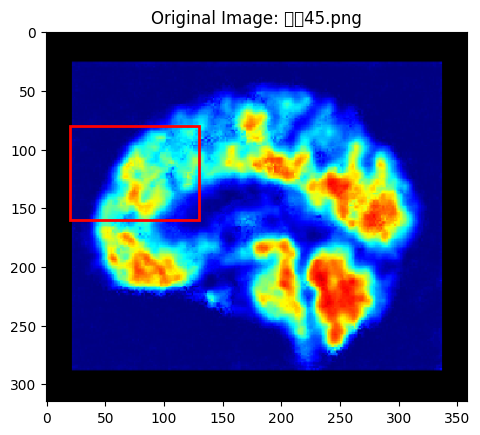

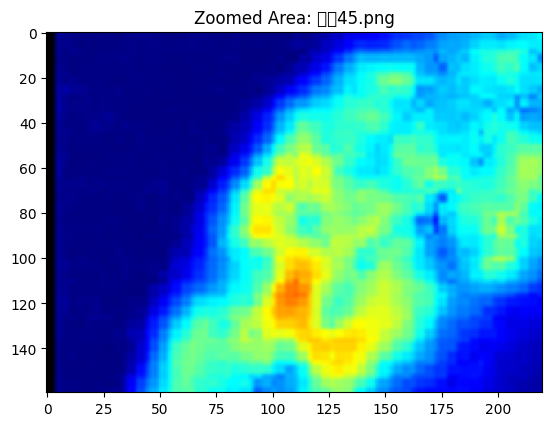

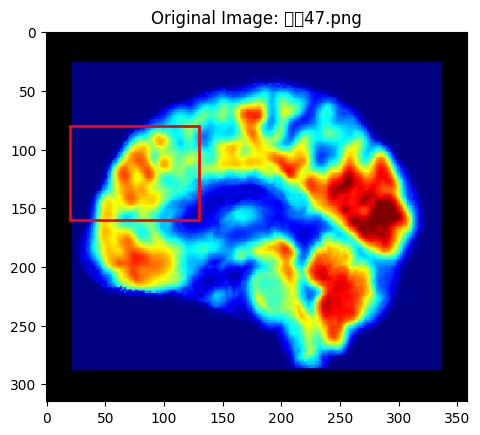

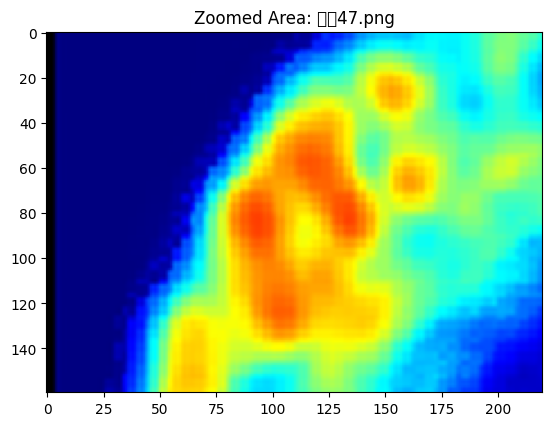

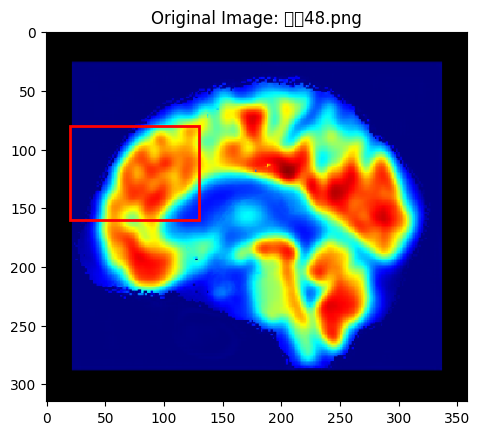

...

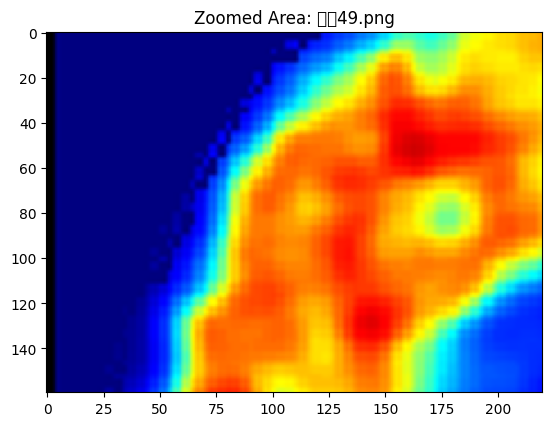

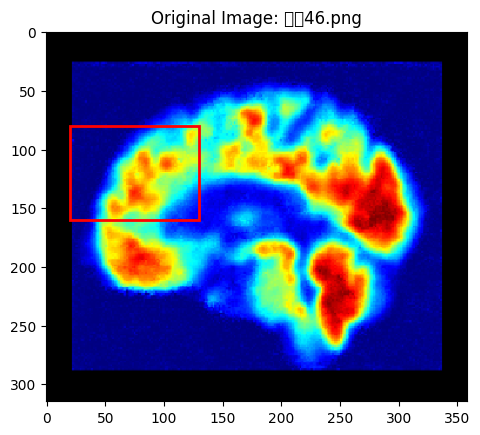

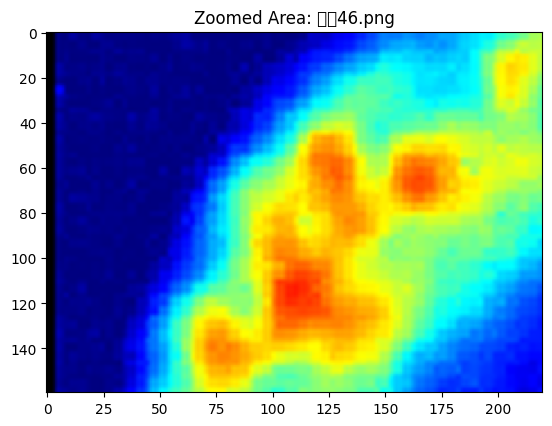

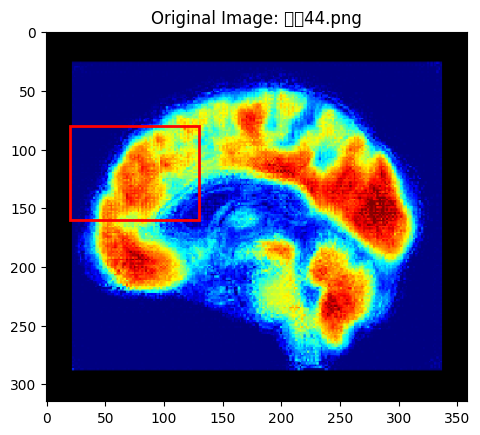

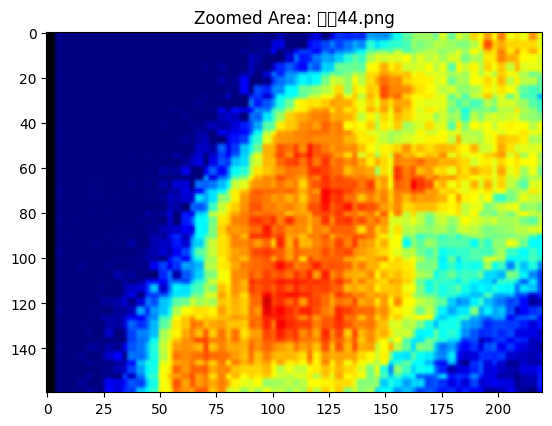

处理完成！放大的图片已保存到文件夹: /home/data/liutuo/code/test/picture_big


In [38]:
import os
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# 定义文件夹路径
input_folder = '/home/data/liutuo/code/test/picture'
output_folder = '/home/data/liutuo/code/test/picture_big'

# 定义感兴趣区域 (left, upper, right, lower)
area_of_interest = (20, 80, 130, 160)
zoom_factor = 2

# 创建输出文件夹
os.makedirs(output_folder, exist_ok=True)

# 遍历文件夹中的所有图片
for filename in os.listdir(input_folder):
    if filename.lower().endswith(('.png')):
        input_path = os.path.join(input_folder, filename)
        output_path = os.path.join(output_folder, f"zoomed_{filename}")
        
        # 加载图片
        image = Image.open(input_path)

        # 裁剪感兴趣区域
        cropped_image = image.crop(area_of_interest)

        # 放大图片
        width, height = cropped_image.size
        resized_image = cropped_image.resize((width * zoom_factor, height * zoom_factor))

        # 保存放大后的图片
        resized_image.save(output_path)

        # 可视化原图与标记区域
        fig, ax = plt.subplots()
        ax.imshow(image)

        # 绘制红色矩形框
        rect = patches.Rectangle(
            (area_of_interest[0], area_of_interest[1]),  # 左上角坐标
            area_of_interest[2] - area_of_interest[0],  # 矩形宽度
            area_of_interest[3] - area_of_interest[1],  # 矩形高度
            linewidth=2,
            edgecolor='red',
            facecolor='none'
        )
        ax.add_patch(rect)
        ax.set_title(f"Original Image: {filename}")
        plt.show()

        # 可视化放大后的图片
        fig, ax = plt.subplots()
        ax.imshow(resized_image)
        ax.set_title(f"Zoomed Area: {filename}")
        plt.show()

print(f"处理完成！放大的图片已保存到文件夹: {output_folder}")


In [40]:
import os
from PIL import Image, ImageDraw

# 定义文件夹路径
input_folder = '/home/data/liutuo/code/test/picture'
output_folder = '/home/data/liutuo/code/test/picture_big'
annotated_folder = os.path.join(output_folder, "annotated_images")

# 定义感兴趣区域 (left, upper, right, lower)
area_of_interest = (20, 80, 130, 160)
zoom_factor = 2

# 创建输出文件夹
os.makedirs(output_folder, exist_ok=True)
os.makedirs(annotated_folder, exist_ok=True)

# 遍历文件夹中的所有图片
for filename in os.listdir(input_folder):
    if filename.lower().endswith('.png'):
        input_path = os.path.join(input_folder, filename)
        zoomed_output_path = os.path.join(output_folder, f"zoomed_{filename}")
        annotated_output_path = os.path.join(annotated_folder, f"annotated_{filename}")
        
        # 加载图片
        image = Image.open(input_path)

        # 裁剪感兴趣区域
        cropped_image = image.crop(area_of_interest)

        # 放大图片
        width, height = cropped_image.size
        resized_image = cropped_image.resize((width * zoom_factor, height * zoom_factor))

        # 保存放大后的图片
        resized_image.save(zoomed_output_path)

        # 创建标注红框的图片
        annotated_image = image.copy()
        draw = ImageDraw.Draw(annotated_image)
        draw.rectangle(
            area_of_interest,
            outline="red",
            width=3  # 红框宽度
        )

        # 保存标注红框的图片
        annotated_image.save(annotated_output_path)

        print(f"Processed: {filename}")

print(f"处理完成！放大的图片和标注图片已保存到文件夹: {output_folder} 和 {annotated_folder}")


Processed: 图片51.png
Processed: 图片53.png
Processed: 图片56.png
Processed: 图片55.png
Processed: 图片54.png
Processed: 图片57.png
Processed: 图片52.png
处理完成！放大的图片和标注图片已保存到文件夹: /home/data/liutuo/code/test/picture_big 和 /home/data/liutuo/code/test/picture_big/annotated_images


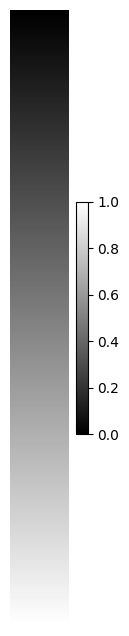

图像已保存到: /home/data/liutuo/code/test/colorbar.png


In [46]:
import matplotlib.pyplot as plt
import numpy as np

# 创建灰度范围
gradient = np.linspace(0, 1, 256).reshape(-1, 1)

# 设置图像大小
fig, ax = plt.subplots(figsize=(1, 8), dpi=100)

# 显示灰度颜色条
im = ax.imshow(gradient, aspect='auto', cmap='gray', extent=[0, 0.1, 0, 1])

# 添加颜色条
cbar = plt.colorbar(im, ax=ax, orientation="vertical", pad=0.1, aspect=20)
cbar.ax.tick_params(labelsize=10)

# 隐藏坐标轴
ax.axis('off')

# 保存图像到指定路径
output_path = "/home/data/liutuo/code/test/colorbar.png"
plt.savefig(output_path, bbox_inches='tight')

# 显示结果
plt.show()

print(f"图像已保存到: {output_path}")


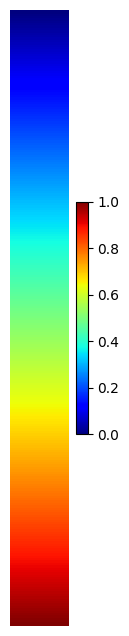

In [47]:
import matplotlib.pyplot as plt
import numpy as np

# 创建颜色范围
gradient = np.linspace(0, 1, 256).reshape(-1, 1)

# 设置图像大小
fig, ax = plt.subplots(figsize=(1, 8), dpi=100)

# 显示彩色颜色条
im = ax.imshow(gradient, aspect='auto', cmap='jet', extent=[0, 0.1, 0, 1])

# 添加颜色条
cbar = plt.colorbar(im, ax=ax, orientation="vertical", pad=0.1, aspect=20)
cbar.ax.tick_params(labelsize=10)

# 隐藏坐标轴
ax.axis('off')
output_path = "/home/data/liutuo/code/test/colorbar.png"
plt.savefig(output_path, bbox_inches='tight')

# 显示结果
plt.show()
